In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import gym
import time 
import matplotlib.pyplot as plt
import random

from collections import namedtuple, deque

In [18]:
# replay buffer to reuse the transitions the agent observed, gotten from the DQN slides 

Transition = namedtuple('Transition',
                        ('state', 'action', 'next_state', 'reward', 'done'))


class ReplayMemory(object):

    def __init__(self, capacity):
        self.memory = deque([], maxlen=capacity)

    def push(self, *args):
        """Save a transition"""
        self.memory.append(Transition(*args))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)

In [4]:
# architecture of the feed forward neural network, gotten from the slides 
import torch.nn.functional as F

class DQN(nn.Module):

    def __init__(self, n_observations, n_actions):
        super(DQN, self).__init__()
        self.layer1 = nn.Linear(n_observations, 128)
        self.layer2 = nn.Linear(128, 128)
        self.layer3 = nn.Linear(128, n_actions)

    def forward(self, x):
        x = F.relu(self.layer1(x))
        x = F.relu(self.layer2(x))
        return self.layer3(x)

In [6]:
# seeds for reproducability, code gotten from the pytorch tutorial provided in dqn slides 

env = gym.make("CartPole-v1")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

seed = 42
random.seed(seed)
torch.manual_seed(seed)
env.reset(seed=seed)
env.action_space.seed(seed)
env.observation_space.seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)



device: cpu


In [13]:
# initializing hyperparameters, again code gotten from pytorch tutorial from DQN slides 
BATCH_SIZE = 128
GAMMA = 0.99
TAU = 0.005
LR = 3e-4


# Get number of actions from gym action space
n_actions = env.action_space.n
# Get the number of state observations
state, info = env.reset()
n_observations = len(state)

policy_net = DQN(n_observations, n_actions).to(device)
target_net = DQN(n_observations, n_actions).to(device)
target_net.load_state_dict(policy_net.state_dict())

optimizer = optim.AdamW(policy_net.parameters(), lr=LR, amsgrad=True)
memory = ReplayMemory(10000)

epsilon = 0.1 
n_episodes = 600 


In [16]:
# action selection function based on fixed exploration rate, this is gotten from the pytorch tutorial but instead of 
#decaying epsilon a fixed epsilon is used. 

def select_action(state):
    state = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
    sample = random.random()
    if sample > epsilon:
        with torch.no_grad():
            # t.max(1) will return the largest column value of each row.
            # second column on max result is index of where max element was
            # found, so we pick action with the larger expected reward.
            return policy_net(state).max(1).indices.view(1, 1)
    else:
        return torch.tensor([[env.action_space.sample()]], device=device, dtype=torch.long)


In [19]:
# training loop for the benchmark DQN, meaning fixed exploration rate and fixed pole length 
rewards_benchmark = []

for episode in range(n_episodes):
    env.unwrapped.length = 1.0        # fixed pole length as a benchmark example 
    state, info = env.reset()
    terminated = False
    truncated = False 
    total_reward = 0

    while not terminated and not truncated:
        #  epsilon-greedy action selection 
        action = select_action(state)

        # taking step in environment 
        next_state, reward, terminated, truncated, _ = env.step(action.item())
        total_reward += reward
        done = terminated or truncated 

        # storing transition
        memory.push(state, action.item(), reward, next_state, done)
        state = next_state

        # DQN update rule according to course slides 
        if len(memory) >= BATCH_SIZE:
            batch = memory.sample(BATCH_SIZE)
            s, a, r, s_next, done_b = zip(*batch)
        
            # below converting to tensors  

            s = torch.tensor(np.array(s), dtype=torch.float32, device=device)
            a = torch.tensor(a, dtype=torch.long, device=device).unsqueeze(1)
            r = torch.tensor(r, dtype=torch.float32,device=device).unsqueeze(1)
            s_next = torch.tensor(np.array(s_next), dtype=torch.float32, device=device)
            done_b = torch.tensor(done_b, dtype=torch.float32, device=device).unsqueeze(1)
            with torch.no_grad():
                next_q_values = target_net(s_next)
                next_q_max = next_q_values.max(dim = 1)[0].unsqueeze(1)
                td_target = r + GAMMA * (1 - done_b) * next_q_max

            current_q = policy_net(s).gather(1,a)
            loss = nn.functional.smooth_l1_loss(current_q, td_target)  # huber loss function 
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Soft update of the target network's weights  (gotten from the pytorch tutorial)
        # θ′ ← τ θ + (1 −τ )θ′
        target_net_state_dict = target_net.state_dict()
        policy_net_state_dict = policy_net.state_dict()
        for key in policy_net_state_dict:
            target_net_state_dict[key] = policy_net_state_dict[key]*TAU + target_net_state_dict[key]*(1-TAU)
        target_net.load_state_dict(target_net_state_dict)

    rewards_benchmark.append(total_reward)
    # below for printing output to track progress of the training 
    if (episode + 1) % 50 == 0:
        avg = np.mean(rewards_benchmark[-50:])
        print(f"[benchmark L=1.0] episode {episode+1} | avg(last 50) = {avg}")
        


[benchmark L=1.0] episode 50 | avg(last 50) = 13.94
[benchmark L=1.0] episode 100 | avg(last 50) = 13.34
[benchmark L=1.0] episode 150 | avg(last 50) = 112.76
[benchmark L=1.0] episode 200 | avg(last 50) = 170.4
[benchmark L=1.0] episode 250 | avg(last 50) = 111.0
[benchmark L=1.0] episode 300 | avg(last 50) = 110.8
[benchmark L=1.0] episode 350 | avg(last 50) = 119.58
[benchmark L=1.0] episode 400 | avg(last 50) = 130.68
[benchmark L=1.0] episode 450 | avg(last 50) = 181.98
[benchmark L=1.0] episode 500 | avg(last 50) = 234.56
[benchmark L=1.0] episode 550 | avg(last 50) = 490.64
[benchmark L=1.0] episode 600 | avg(last 50) = 498.8


In [29]:
# saving weights after training 

torch.save(policy_net.state_dict(), "/Users/lukachkadua/Desktop/benchmark_fixed_L.pth")


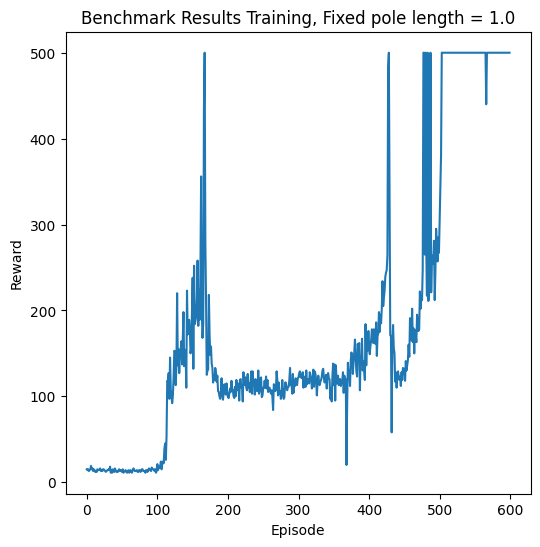

In [33]:
def plot_results(results):
    
    plt.figure(figsize=(6, 6))
    plt.title("Benchmark Results Training, Fixed pole length = 1.0")
    plt.plot(results)
    plt.xlabel("Episode")
    plt.ylabel("Reward")
    plt.savefig("/Users/lukachkadua/Desktop/benchmark_curve.png", dpi=150, bbox_inches="tight")
    plt.show()

plot_results(rewards_benchmark)

In [41]:
# testing the trained benchmarks, with the functions provided in test_script.py 

def test_pole_length(env, q_network):
    """
    This function runs your trained network on a specific pole length
    You are not allowed to change this function
    """

    wind = 25
    state = env.reset()[0]
    state = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
    done = False
    total_reward = 0


    while not done:

        action = q_network(state).argmax().item()
        next_state, reward, done, _, __ = env.step(action)
        next_state = torch.tensor(next_state, dtype=torch.float32).unsqueeze(0)
        state = next_state
        total_reward += reward

        if total_reward >= 500 and total_reward <= 1000:
            if total_reward % wind == 0:

                env.unwrapped.force_mag = 75

        if total_reward > 1000:
            env.unwrapped.force_mag = 25 + (0.01 * total_reward)

    return total_reward



In [47]:
def bar_plot(results):
    data = results[0]

    avgs = {k: v for k, v in data.items() if k.startswith('Avg_')}
    stds = {k.replace('Avg', 'Std'): data[k.replace('Avg', 'Std')] for k in avgs.keys()}

    sorted_keys = sorted(avgs.keys(), key=lambda x: float(x.split('_')[1]))
    avg_values = [avgs[k] for k in sorted_keys]
    std_values = [stds[k.replace('Avg', 'Std')] for k in sorted_keys]

    overall_avg = np.mean(np.array(avg_values))

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(avg_values)), avg_values, yerr=std_values, capsize=5, alpha=0.7)
    plt.xticks(range(len(avg_values)), [k.split('_')[1] for k in sorted_keys])
    plt.xticks(rotation = 45)
    plt.xlabel('Pole length')
    plt.ylabel('Episode length')
    plt.title(f'Average score over all pole lengths = {round(overall_avg, 0)}')

    plt.savefig("/Users/lukachkadua/bar_plot.png")
    plt.show()

0.4
0.4482758620689655
0.496551724137931
0.5448275862068965
0.5931034482758621
0.6413793103448275
0.6896551724137931
0.7379310344827587
0.7862068965517242
0.8344827586206897
0.8827586206896552
0.9310344827586207
0.9793103448275863
1.0275862068965518
1.0758620689655172
1.1241379310344828
1.1724137931034484
1.2206896551724138
1.2689655172413792
1.3172413793103448
1.3655172413793104
1.4137931034482758
1.4620689655172412
1.510344827586207
1.5586206896551724
1.6068965517241378
1.6551724137931036
1.703448275862069
1.7517241379310344
1.8


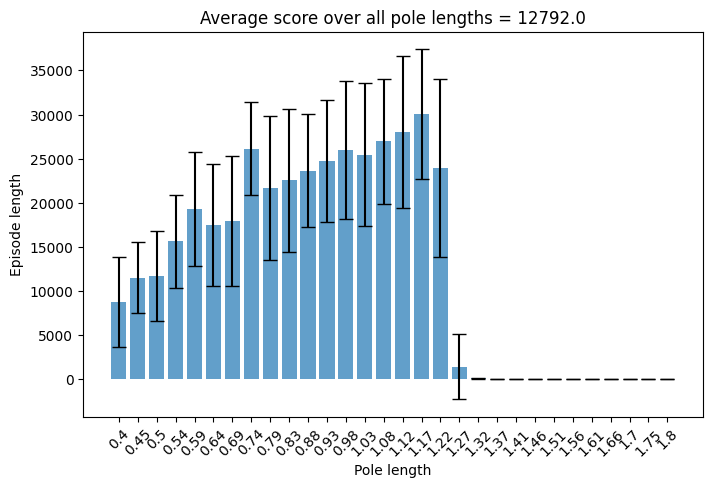

In [48]:
import pandas as pd 

def test_script():
    """
    Function that simulates the trained NN over 30 different pole lengths, 10 times per length.
    """

    pole_lengths = np.linspace(0.4, 1.8, 30)
    all_results = []

    # import here your trained neural network
    trained_nn = '/Users/lukachkadua/Desktop/benchmark_fixed_L.pth'

    results = {}
    total_score = 0

    for length in pole_lengths:
        print(length)

        pole_score = []

        for x in range(10):

            env = gym.make('CartPole-v1')
            env.unwrapped.length = length

            state_dim = env.observation_space.shape[0]
            action_dim = env.action_space.n
            loaded_model = DQN(state_dim, action_dim)
            loaded_model.load_state_dict(torch.load(trained_nn, weights_only=True))

            # Switch to evaluation mode
            loaded_model.eval()  # Use for inference
            score = test_pole_length(env, loaded_model)
            pole_score.append(score)

        mean_score = np.mean(np.array(pole_score))
        std_score = np.std(np.array(pole_score))

        total_score += mean_score

        results[f"Avg_{round(length, 2)}"] = mean_score  # Store just the mean
        results[f"Std_{round(length, 2)}"] = std_score  # Store std separately

    results["Total"] = total_score  # Store just the mean
    all_results.append(results)

    bar_plot(all_results)

    # Convert list to DataFrame
    df = pd.DataFrame(all_results)
    df.to_excel("/Users/lukachkadua/experiment_results.xlsx", index=False)
    df.to_csv("/Users/lukachkadua/experiment_results_benchmark.csv", index=False) # added this to save resutls as csv file 

if __name__ == "__main__":
    test_script()


Now we basically repeat and reuse the code from above, but now training the 3 different strategies, first starting with the strategy where the pole length is uniformly picked at random 

In [49]:
# training loop for the uniform sampling of pole length strategy resuing code from beofre DQN 
# reseeding, code from the pytorch tutorial 
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
env.reset(seed=seed)
env.action_space.seed(seed)
env.observation_space.seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)



rewards_uniform = []

for episode in range(n_episodes):
    env.unwrapped.length = np.random.uniform(0.4,1.8)       # pole length is sampled uniformly at random per episode
    state, info = env.reset()
    terminated = False
    truncated = False 
    total_reward = 0

    while not terminated and not truncated:
        #  epsilon-greedy action selection 
        action = select_action(state)

        # taking step in environment 
        next_state, reward, terminated, truncated, _ = env.step(action.item())
        total_reward += reward
        done = terminated or truncated 

        # storing transition
        memory.push(state, action.item(), reward, next_state, done)
        state = next_state

        # DQN update rule 
        if len(memory) >= BATCH_SIZE:
            batch = memory.sample(BATCH_SIZE)
            s, a, r, s_next, done_b = zip(*batch)
        
            # below converting to tensors 

            s = torch.tensor(np.array(s), dtype=torch.float32, device=device)
            a = torch.tensor(a, dtype=torch.long, device=device).unsqueeze(1)
            r = torch.tensor(r, dtype=torch.float32,device=device).unsqueeze(1)
            s_next = torch.tensor(np.array(s_next), dtype=torch.float32, device=device)
            done_b = torch.tensor(done_b, dtype=torch.float32, device=device).unsqueeze(1)
            with torch.no_grad():
                next_q_values = target_net(s_next)
                next_q_max = next_q_values.max(dim = 1)[0].unsqueeze(1)
                td_target = r + GAMMA * (1 - done_b) * next_q_max

            current_q = policy_net(s).gather(1,a)
            loss = nn.functional.smooth_l1_loss(current_q, td_target)  # huber loss function 
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Soft update of the target network's weights  (gotten from the pytorch tutorial)
        # θ′ ← τ θ + (1 −τ )θ′
        target_net_state_dict = target_net.state_dict()
        policy_net_state_dict = policy_net.state_dict()
        for key in policy_net_state_dict:
            target_net_state_dict[key] = policy_net_state_dict[key]*TAU + target_net_state_dict[key]*(1-TAU)
        target_net.load_state_dict(target_net_state_dict)

    rewards_uniform.append(total_reward)
    if (episode + 1) % 50 == 0:
        avg = np.mean(rewards_uniform[-50:])
        print(f"[benchmark L=1.0] episode {episode+1} | avg(last 50) = {avg}")
        


[benchmark L=1.0] episode 50 | avg(last 50) = 375.48
[benchmark L=1.0] episode 100 | avg(last 50) = 490.94
[benchmark L=1.0] episode 150 | avg(last 50) = 391.24
[benchmark L=1.0] episode 200 | avg(last 50) = 378.64
[benchmark L=1.0] episode 250 | avg(last 50) = 450.4
[benchmark L=1.0] episode 300 | avg(last 50) = 484.72
[benchmark L=1.0] episode 350 | avg(last 50) = 402.1
[benchmark L=1.0] episode 400 | avg(last 50) = 397.02
[benchmark L=1.0] episode 450 | avg(last 50) = 467.92
[benchmark L=1.0] episode 500 | avg(last 50) = 402.54
[benchmark L=1.0] episode 550 | avg(last 50) = 418.78
[benchmark L=1.0] episode 600 | avg(last 50) = 473.38


In [50]:
torch.save(policy_net.state_dict(), "/Users/lukachkadua/Desktop/strategy_uniform_L.pth")


In [ ]:
plot_results(rewards_uniform)
# not fixed pole length but uniform

0.4
0.4482758620689655
0.496551724137931
0.5448275862068965
0.5931034482758621
0.6413793103448275
0.6896551724137931
0.7379310344827587
0.7862068965517242
0.8344827586206897
0.8827586206896552
0.9310344827586207
0.9793103448275863
1.0275862068965518
1.0758620689655172
1.1241379310344828
1.1724137931034484
1.2206896551724138
1.2689655172413792
1.3172413793103448
1.3655172413793104
1.4137931034482758
1.4620689655172412
1.510344827586207
1.5586206896551724
1.6068965517241378
1.6551724137931036
1.703448275862069
1.7517241379310344
1.8


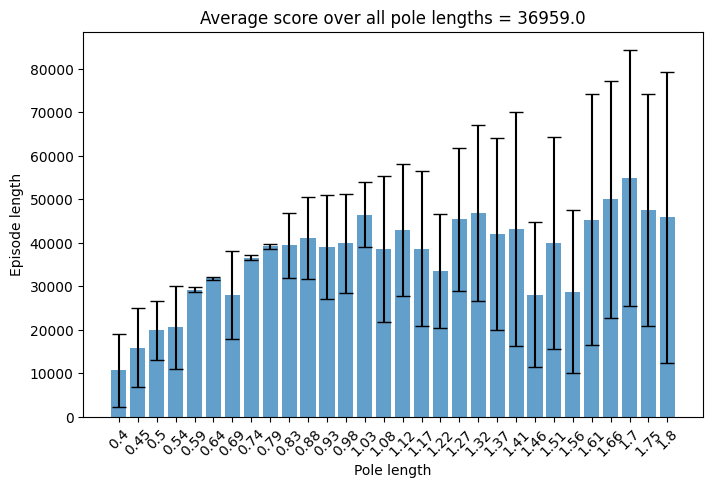

In [52]:
def bar_plot(results):
    data = results[0]

    avgs = {k: v for k, v in data.items() if k.startswith('Avg_')}
    stds = {k.replace('Avg', 'Std'): data[k.replace('Avg', 'Std')] for k in avgs.keys()}

    sorted_keys = sorted(avgs.keys(), key=lambda x: float(x.split('_')[1]))
    avg_values = [avgs[k] for k in sorted_keys]
    std_values = [stds[k.replace('Avg', 'Std')] for k in sorted_keys]

    overall_avg = np.mean(np.array(avg_values))

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(avg_values)), avg_values, yerr=std_values, capsize=5, alpha=0.7)
    plt.xticks(range(len(avg_values)), [k.split('_')[1] for k in sorted_keys])
    plt.xticks(rotation = 45)
    plt.xlabel('Pole length')
    plt.ylabel('Episode length')
    plt.title(f'Average score over all pole lengths = {round(overall_avg, 0)}')

    plt.savefig("/Users/lukachkadua/bar_plot_uniform.png")
    plt.show()

def test_script():
    """
    Function that simulates the trained NN over 30 different pole lengths, 10 times per length.
    """

    pole_lengths = np.linspace(0.4, 1.8, 30)
    all_results = []

    # import here your trained neural network
    trained_nn = '/Users/lukachkadua/Desktop/strategy_uniform_L.pth'

    results = {}
    total_score = 0

    for length in pole_lengths:
        print(length)

        pole_score = []

        for x in range(10):

            env = gym.make('CartPole-v1')
            env.unwrapped.length = length

            state_dim = env.observation_space.shape[0]
            action_dim = env.action_space.n
            loaded_model = DQN(state_dim, action_dim)
            loaded_model.load_state_dict(torch.load(trained_nn, weights_only=True))

            # Switch to evaluation mode
            loaded_model.eval()  # Use for inference
            score = test_pole_length(env, loaded_model)
            pole_score.append(score)

        mean_score = np.mean(np.array(pole_score))
        std_score = np.std(np.array(pole_score))

        total_score += mean_score

        results[f"Avg_{round(length, 2)}"] = mean_score  # Store just the mean
        results[f"Std_{round(length, 2)}"] = std_score  # Store std separately

    results["Total"] = total_score  # Store just the mean
    all_results.append(results)

    bar_plot(all_results)

    # Convert list to DataFrame
    df = pd.DataFrame(all_results)
    df.to_excel("/Users/lukachkadua/experiment_results_uniform.xlsx", index=False)
    df.to_csv("/Users/lukachkadua/experiment_results_uniform.csv", index=False) # added this to save resutls as csv file 

if __name__ == "__main__":
    test_script()


Now for the linearly increasing pole length sampling strategy, we simply again reuse all the code from before with slight changes in the training loop for sampling pole length 

In [56]:
# training loop for the linearly increasing sampling of pole length strategy resuing code from beofre 
# reseeding, code from the pytorch tutorial 
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
env.reset(seed=seed)
env.action_space.seed(seed)
env.observation_space.seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)



rewards_linear = []

for episode in range(n_episodes):
    env.unwrapped.length = 0.4 + (episode/n_episodes) * (1.8-0.4)       # pole length is sampled in an icreasing fashion linearly from 0.4 to 1.8 
    state, info = env.reset()
    terminated = False
    truncated = False 
    total_reward = 0

    while not terminated and not truncated:
        #  epsilon-greedy action selection 
        action = select_action(state)

        # taking step in environment 
        next_state, reward, terminated, truncated, _ = env.step(action.item())
        total_reward += reward
        done = terminated or truncated 

        # storing transition
        memory.push(state, action.item(), reward, next_state, done)
        state = next_state

        # DQN update rule 
        if len(memory) >= BATCH_SIZE:
            batch = memory.sample(BATCH_SIZE)
            s, a, r, s_next, done_b = zip(*batch)
        
            # below converting to tensors 

            s = torch.tensor(np.array(s), dtype=torch.float32, device=device)
            a = torch.tensor(a, dtype=torch.long, device=device).unsqueeze(1)
            r = torch.tensor(r, dtype=torch.float32,device=device).unsqueeze(1)
            s_next = torch.tensor(np.array(s_next), dtype=torch.float32, device=device)
            done_b = torch.tensor(done_b, dtype=torch.float32, device=device).unsqueeze(1)
            with torch.no_grad():
                next_q_values = target_net(s_next)
                next_q_max = next_q_values.max(dim = 1)[0].unsqueeze(1)
                td_target = r + GAMMA * (1 - done_b) * next_q_max

            current_q = policy_net(s).gather(1,a)
            loss = nn.functional.smooth_l1_loss(current_q, td_target)  # huber loss function 
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Soft update of the target network's weights  (gotten from the pytorch tutorial)
        # θ′ ← τ θ + (1 −τ )θ′
        target_net_state_dict = target_net.state_dict()
        policy_net_state_dict = policy_net.state_dict()
        for key in policy_net_state_dict:
            target_net_state_dict[key] = policy_net_state_dict[key]*TAU + target_net_state_dict[key]*(1-TAU)
        target_net.load_state_dict(target_net_state_dict)

    rewards_linear.append(total_reward)
    if (episode + 1) % 50 == 0:
        avg = np.mean(rewards_uniform[-50:])
        print(f"[benchmark L=1.0] episode {episode+1} | avg(last 50) = {avg}")
        


[benchmark L=1.0] episode 50 | avg(last 50) = 69.76
[benchmark L=1.0] episode 100 | avg(last 50) = 69.76
[benchmark L=1.0] episode 150 | avg(last 50) = 69.76
[benchmark L=1.0] episode 200 | avg(last 50) = 69.76
[benchmark L=1.0] episode 250 | avg(last 50) = 69.76
[benchmark L=1.0] episode 300 | avg(last 50) = 69.76
[benchmark L=1.0] episode 350 | avg(last 50) = 69.76
[benchmark L=1.0] episode 400 | avg(last 50) = 69.76
[benchmark L=1.0] episode 450 | avg(last 50) = 69.76
[benchmark L=1.0] episode 500 | avg(last 50) = 69.76
[benchmark L=1.0] episode 550 | avg(last 50) = 69.76
[benchmark L=1.0] episode 600 | avg(last 50) = 69.76


In [57]:
torch.save(policy_net.state_dict(), "/Users/lukachkadua/Desktop/strategy_linear_L.pth")


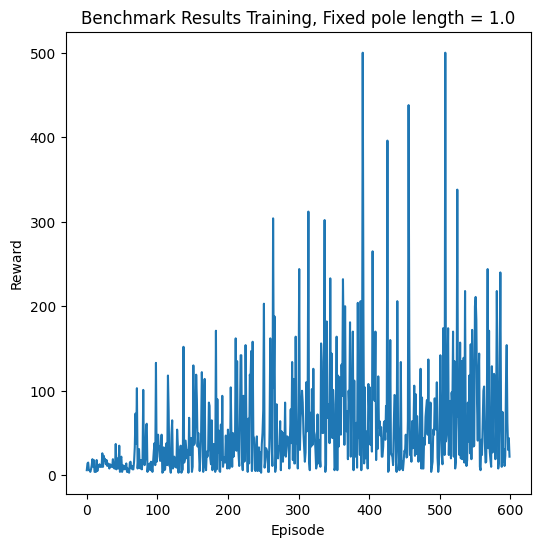

In [59]:
plot_results(rewards_linear)

0.4
0.4482758620689655
0.496551724137931
0.5448275862068965
0.5931034482758621
0.6413793103448275
0.6896551724137931
0.7379310344827587
0.7862068965517242
0.8344827586206897
0.8827586206896552
0.9310344827586207
0.9793103448275863
1.0275862068965518
1.0758620689655172
1.1241379310344828
1.1724137931034484
1.2206896551724138
1.2689655172413792
1.3172413793103448
1.3655172413793104
1.4137931034482758
1.4620689655172412
1.510344827586207
1.5586206896551724
1.6068965517241378
1.6551724137931036
1.703448275862069
1.7517241379310344
1.8


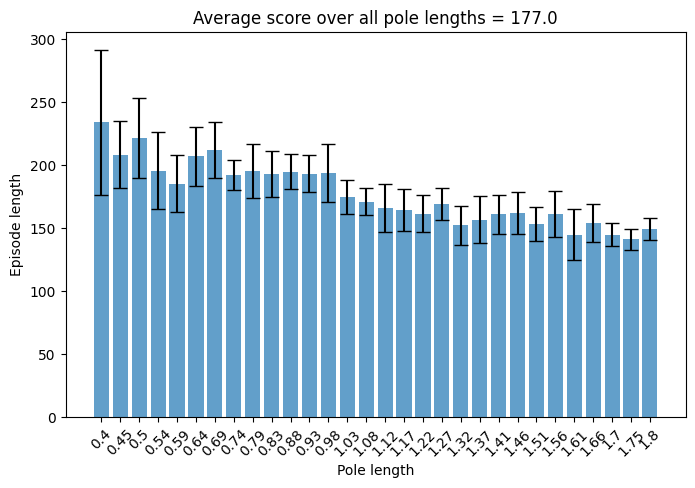

In [60]:
def bar_plot(results):
    data = results[0]

    avgs = {k: v for k, v in data.items() if k.startswith('Avg_')}
    stds = {k.replace('Avg', 'Std'): data[k.replace('Avg', 'Std')] for k in avgs.keys()}

    sorted_keys = sorted(avgs.keys(), key=lambda x: float(x.split('_')[1]))
    avg_values = [avgs[k] for k in sorted_keys]
    std_values = [stds[k.replace('Avg', 'Std')] for k in sorted_keys]

    overall_avg = np.mean(np.array(avg_values))

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(avg_values)), avg_values, yerr=std_values, capsize=5, alpha=0.7)
    plt.xticks(range(len(avg_values)), [k.split('_')[1] for k in sorted_keys])
    plt.xticks(rotation = 45)
    plt.xlabel('Pole length')
    plt.ylabel('Episode length')
    plt.title(f'Average score over all pole lengths = {round(overall_avg, 0)}')

    plt.savefig("/Users/lukachkadua/bar_plot_linear.png")
    plt.show()

def test_script():
    """
    Function that simulates the trained NN over 30 different pole lengths, 10 times per length.
    """

    pole_lengths = np.linspace(0.4, 1.8, 30)
    all_results = []

    # import here your trained neural network
    trained_nn = '/Users/lukachkadua/Desktop/strategy_linear_L.pth'

    results = {}
    total_score = 0

    for length in pole_lengths:
        print(length)

        pole_score = []

        for x in range(10):

            env = gym.make('CartPole-v1')
            env.unwrapped.length = length

            state_dim = env.observation_space.shape[0]
            action_dim = env.action_space.n
            loaded_model = DQN(state_dim, action_dim)
            loaded_model.load_state_dict(torch.load(trained_nn, weights_only=True))

            # Switch to evaluation mode
            loaded_model.eval()  # Use for inference
            score = test_pole_length(env, loaded_model)
            pole_score.append(score)

        mean_score = np.mean(np.array(pole_score))
        std_score = np.std(np.array(pole_score))

        total_score += mean_score

        results[f"Avg_{round(length, 2)}"] = mean_score  # Store just the mean
        results[f"Std_{round(length, 2)}"] = std_score  # Store std separately

    results["Total"] = total_score  # Store just the mean
    all_results.append(results)

    bar_plot(all_results)

    # Convert list to DataFrame
    df = pd.DataFrame(all_results)
    df.to_excel("/Users/lukachkadua/experiment_results_linear.xlsx", index=False)
    df.to_csv("/Users/lukachkadua/experiment_results_linear.csv", index=False) # added this to save resutls as csv file 

if __name__ == "__main__":
    test_script()


Now the strategy of decaying exploration rate 

In [65]:
# actin selection function for decaying exploration rate, taken from the PyTorch tutorial from DQN slides 
import math 

EPS_START = 0.9
EPS_END = 0.01
EPS_DECAY = 2500

steps_done = 0 

def select_action_decay(state):
    global steps_done
    state = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
    sample = random.random()
    eps_threshold = EPS_END + (EPS_START - EPS_END) * \
        math.exp(-1. * steps_done / EPS_DECAY)
    steps_done += 1
    if sample > eps_threshold:
        with torch.no_grad():
            # t.max(1) will return the largest column value of each row.
            # second column on max result is index of where max element was
            # found, so we pick action with the larger expected reward.
            return policy_net(state).max(1).indices.view(1, 1)
    else:
        return torch.tensor([[env.action_space.sample()]], device=device, dtype=torch.long)


In [66]:
# training loop for the uniform sampling of pole length and decaying exploration rate strategy resuing code from beofre 
# reseeding, code from the pytorch tutorial 
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
env.reset(seed=seed)
env.action_space.seed(seed)
env.observation_space.seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)



rewards_decay = []

for episode in range(n_episodes):
    env.unwrapped.length = np.random.uniform(0.4,1.8)        # uniformly sampled at random 
    state, info = env.reset()
    terminated = False
    truncated = False 
    total_reward = 0

    while not terminated and not truncated:
        #  decaying epsilon-greedy action selection 
        action = select_action_decay(state)

        # taking step in environment 
        next_state, reward, terminated, truncated, _ = env.step(action.item())
        total_reward += reward
        done = terminated or truncated 

        # storing transition
        memory.push(state, action.item(), reward, next_state, done)
        state = next_state

        # DQN update rule 
        if len(memory) >= BATCH_SIZE:
            batch = memory.sample(BATCH_SIZE)
            s, a, r, s_next, done_b = zip(*batch)
        
            # below converting to tensors  

            s = torch.tensor(np.array(s), dtype=torch.float32, device=device)
            a = torch.tensor(a, dtype=torch.long, device=device).unsqueeze(1)
            r = torch.tensor(r, dtype=torch.float32,device=device).unsqueeze(1)
            s_next = torch.tensor(np.array(s_next), dtype=torch.float32, device=device)
            done_b = torch.tensor(done_b, dtype=torch.float32, device=device).unsqueeze(1)
            with torch.no_grad():
                next_q_values = target_net(s_next)
                next_q_max = next_q_values.max(dim = 1)[0].unsqueeze(1)
                td_target = r + GAMMA * (1 - done_b) * next_q_max

            current_q = policy_net(s).gather(1,a)
            loss = nn.functional.smooth_l1_loss(current_q, td_target)  # huber loss function 
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Soft update of the target network's weights  (gotten from the pytorch tutorial)
        # θ′ ← τ θ + (1 −τ )θ′
        target_net_state_dict = target_net.state_dict()
        policy_net_state_dict = policy_net.state_dict()
        for key in policy_net_state_dict:
            target_net_state_dict[key] = policy_net_state_dict[key]*TAU + target_net_state_dict[key]*(1-TAU)
        target_net.load_state_dict(target_net_state_dict)

    rewards_decay.append(total_reward)
    if (episode + 1) % 50 == 0:
        avg = np.mean(rewards_uniform[-50:])
        print(f"[benchmark L=1.0] episode {episode+1} | avg(last 50) = {avg}")
        


[benchmark L=1.0] episode 50 | avg(last 50) = 69.76
[benchmark L=1.0] episode 100 | avg(last 50) = 69.76
[benchmark L=1.0] episode 150 | avg(last 50) = 69.76
[benchmark L=1.0] episode 200 | avg(last 50) = 69.76
[benchmark L=1.0] episode 250 | avg(last 50) = 69.76
[benchmark L=1.0] episode 300 | avg(last 50) = 69.76
[benchmark L=1.0] episode 350 | avg(last 50) = 69.76
[benchmark L=1.0] episode 400 | avg(last 50) = 69.76
[benchmark L=1.0] episode 450 | avg(last 50) = 69.76
[benchmark L=1.0] episode 500 | avg(last 50) = 69.76
[benchmark L=1.0] episode 550 | avg(last 50) = 69.76
[benchmark L=1.0] episode 600 | avg(last 50) = 69.76


In [67]:
torch.save(policy_net.state_dict(), "/Users/lukachkadua/Desktop/strategy_decay_L.pth")


0.4
0.4482758620689655
0.496551724137931
0.5448275862068965
0.5931034482758621
0.6413793103448275
0.6896551724137931
0.7379310344827587
0.7862068965517242
0.8344827586206897
0.8827586206896552
0.9310344827586207
0.9793103448275863
1.0275862068965518
1.0758620689655172
1.1241379310344828
1.1724137931034484
1.2206896551724138
1.2689655172413792
1.3172413793103448
1.3655172413793104
1.4137931034482758
1.4620689655172412
1.510344827586207
1.5586206896551724
1.6068965517241378
1.6551724137931036
1.703448275862069
1.7517241379310344
1.8


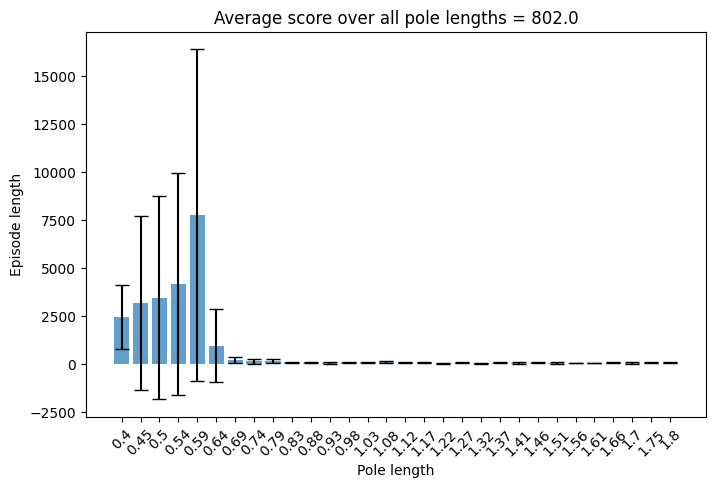

In [68]:
def bar_plot(results):
    data = results[0]

    avgs = {k: v for k, v in data.items() if k.startswith('Avg_')}
    stds = {k.replace('Avg', 'Std'): data[k.replace('Avg', 'Std')] for k in avgs.keys()}

    sorted_keys = sorted(avgs.keys(), key=lambda x: float(x.split('_')[1]))
    avg_values = [avgs[k] for k in sorted_keys]
    std_values = [stds[k.replace('Avg', 'Std')] for k in sorted_keys]

    overall_avg = np.mean(np.array(avg_values))

    plt.figure(figsize=(8, 5))
    plt.bar(range(len(avg_values)), avg_values, yerr=std_values, capsize=5, alpha=0.7)
    plt.xticks(range(len(avg_values)), [k.split('_')[1] for k in sorted_keys])
    plt.xticks(rotation = 45)
    plt.xlabel('Pole length')
    plt.ylabel('Episode length')
    plt.title(f'Average score over all pole lengths = {round(overall_avg, 0)}')

    plt.savefig("/Users/lukachkadua/bar_plot_decay.png")
    plt.show()

def test_script():
    """
    Function that simulates the trained NN over 30 different pole lengths, 10 times per length.
    """

    pole_lengths = np.linspace(0.4, 1.8, 30)
    all_results = []

    # import here your trained neural network
    trained_nn = '/Users/lukachkadua/Desktop/strategy_decay_L.pth'

    results = {}
    total_score = 0

    for length in pole_lengths:
        print(length)

        pole_score = []

        for x in range(10):

            env = gym.make('CartPole-v1')
            env.unwrapped.length = length

            state_dim = env.observation_space.shape[0]
            action_dim = env.action_space.n
            loaded_model = DQN(state_dim, action_dim)
            loaded_model.load_state_dict(torch.load(trained_nn, weights_only=True))

            # Switch to evaluation mode
            loaded_model.eval()  # Use for inference
            score = test_pole_length(env, loaded_model)
            pole_score.append(score)

        mean_score = np.mean(np.array(pole_score))
        std_score = np.std(np.array(pole_score))

        total_score += mean_score

        results[f"Avg_{round(length, 2)}"] = mean_score  # Store just the mean
        results[f"Std_{round(length, 2)}"] = std_score  # Store std separately

    results["Total"] = total_score  # Store just the mean
    all_results.append(results)

    bar_plot(all_results)

    # Convert list to DataFrame
    df = pd.DataFrame(all_results)
    df.to_excel("/Users/lukachkadua/experiment_results_decay.xlsx", index=False)
    df.to_csv("/Users/lukachkadua/experiment_results_decay.csv", index=False) # added this to save resutls as csv file 

if __name__ == "__main__":
    test_script()
